# Тематическое моделирование отзывов

Исследование кластеризации отзывов с эмбеддингами предложений и TF-IDF: UMAP, DBSCAN, ключевые слова и метрики качества кластеров.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk

In [2]:
df = pd.read_csv(r'../../data/Reviews.csv')

In [3]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [4]:
df = df['Text']

In [5]:
df.head()

0    I have bought several of the Vitality canned d...
1    Product arrived labeled as Jumbo Salted Peanut...
2    This is a confection that has been around a fe...
3    If you are looking for the secret ingredient i...
4    Great taffy at a great price.  There was a wid...
Name: Text, dtype: object

In [6]:
n = 10000
df = df[:n]

# Предобработка текста

In [7]:
import re

In [8]:
df = df.map(lambda x: re.sub(r'[^a-z\s]', '', x, flags=re.IGNORECASE))

In [9]:
df = df.map(lambda x: x.lower())

In [10]:
df = df.map(lambda x: re.sub(r'\s+', ' ', x).strip())

In [11]:
df = df.map(lambda x: '\n'.join([line.strip() for line in x.split('\n')]))

In [12]:
from nltk.corpus import stopwords

nltk.download('stopwords')
stopwords = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Denis\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [13]:
df = df.map(lambda x: ' '.join([word for word in x.split() if word not in stopwords]))

In [14]:
import spacy
sp = spacy.load("en_core_web_sm")
df = df.map(lambda x: ' '.join(token.lemma_ for token in sp(x)))

In [15]:
docs = df.copy()

In [16]:
df.head()

0    buy several vitality can dog food product find...
1    product arrive label jumbo salt peanutsthe pea...
2    confection around century light pillowy citrus...
3    look secret ingredient robitussin believe find...
4    great taffy great price wide assortment yummy ...
Name: Text, dtype: object

# Кодирование текста

In [17]:
from sentence_transformers import SentenceTransformer

In [18]:
import torch

In [19]:
embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

In [20]:
emb = embedding_model.encode(df)

In [21]:
emb = torch.tensor(emb)

In [22]:
emb.size()

torch.Size([10000, 384])

In [23]:
emb = emb.numpy()

# Понижаем размерность

In [24]:
from umap import UMAP

In [25]:
u = UMAP(n_components=2, n_neighbors=10).fit(emb)
emb_umap = u.transform(emb)

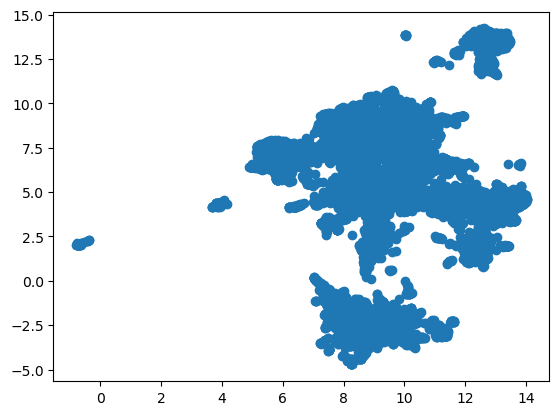

In [26]:
plt.scatter(emb_umap[:, 0], emb_umap[:, 1])

# Кластеризация

In [27]:
from sklearn.cluster import DBSCAN

In [90]:
dbscan = DBSCAN(eps=0.3, min_samples=5).fit(emb_umap)

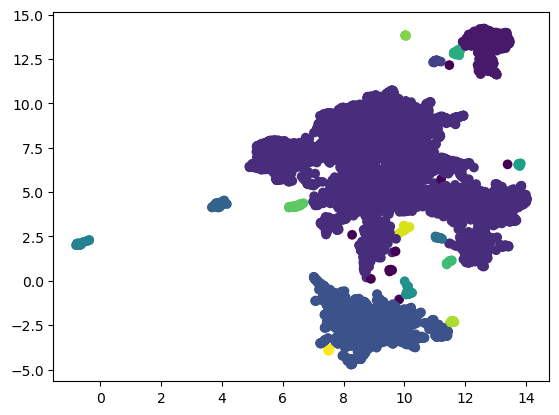

In [91]:
plt.scatter(emb_umap[:, 0], emb_umap[:, 1], c=dbscan.labels_)

In [92]:
len(np.unique(dbscan.labels_))

17

In [93]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [94]:
labels = dbscan.labels_

In [95]:
silhouette = silhouette_score(
    emb_umap,
    labels
)

In [96]:
dbi = davies_bouldin_score(
    emb_umap,
    labels
)

In [97]:
print("Silhouette:", silhouette)
print("DB:", dbi)

Silhouette: -0.1655239
DB: 3.1654410738615146


In [98]:
df_sbert_topics = pd.DataFrame({
    'doc': docs[:n],
    'topic': dbscan.labels_
})

In [99]:
df_sbert_topics['topic'].value_counts()

topic
 1     7020
 3     1764
 0      774
 4      106
 6       85
 11      55
 2       46
 7       37
 9       18
 8       17
 13      17
 5       13
 15      12
-1       11
 10       9
 12       8
 14       8
Name: count, dtype: int64

# Объединяем документы одного класса в один документ

In [100]:
docs_per_class = df_sbert_topics.groupby(['topic'], as_index=False).agg({'doc': ' '.join})

In [101]:
docs_per_class.head()

,topic,doc
0,-1,love convenience single good creamer aroundtas...
1,0,buy several vitality can dog food product find...
2,1,product arrive label jumbo salt peanutsthe pea...
3,2,right I m mostly sprout cat eat grass love rot...
4,3,never huge coffee fan however mother purchase ...


In [102]:
from keybert import KeyBERT

In [103]:
kw_model = KeyBERT()
keywords = kw_model.extract_keywords(docs_per_class['doc'], keyphrase_ngram_range=(1, 2), stop_words='english', top_n=15)

# Топовые слова

In [104]:
keywords

[[('keurig iced', 0.602),
  ('keurig', 0.5822),
  ('use keurig', 0.5729),
  ('keurig taste', 0.5724),
  ('right keurig', 0.556),
  ('purchase keurig', 0.5496),
  ('keurig work', 0.5458),
  ('keurig husband', 0.5102),
  ('ice brew', 0.5082),
  ('keurig model', 0.5025),
  ('brew kcup', 0.4951),
  ('fit keurig', 0.4923),
  ('ice brewing', 0.4864),
  ('cup brew', 0.4758),
  ('brew', 0.4662)],
 [('dog foodsadly', 0.6418),
  ('dog foodoh', 0.5963),
  ('dog foodsi', 0.5953),
  ('dog foodbr', 0.5869),
  ('dog food', 0.5856),
  ('dog diet', 0.5586),
  ('nutrition dog', 0.5545),
  ('dog meal', 0.5507),
  ('food dogbut', 0.5467),
  ('food dog', 0.5382),
  ('diet dog', 0.5198),
  ('dog ingredient', 0.5125),
  ('pet foodbr', 0.5119),
  ('dog foodi', 0.5108),
  ('pet food', 0.5082)],
 [('flavor list', 0.5566),
  ('alternative candy', 0.5408),
  ('sweetspicy flavor', 0.5404),
  ('flavor grocery', 0.5399),
  ('flavor candy', 0.5396),
  ('flavorful snack', 0.5393),
  ('list flavor', 0.5349),
  ('flavor

In [105]:
from wordcloud import WordCloud

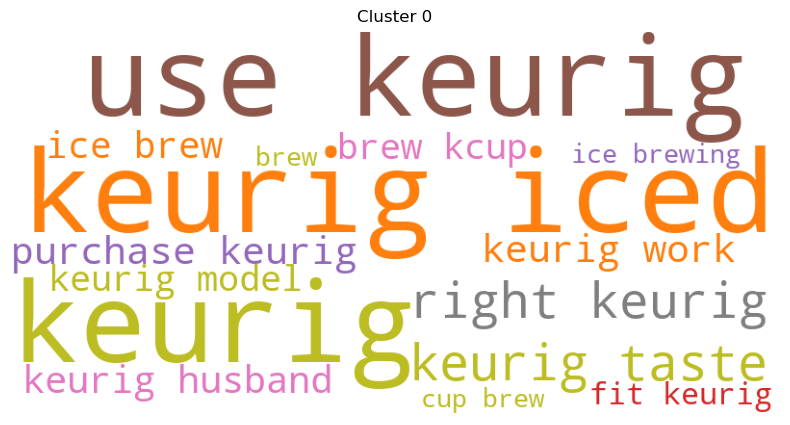

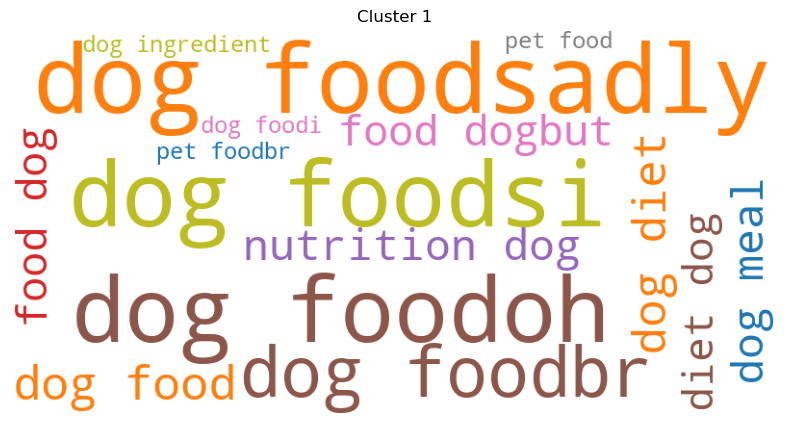

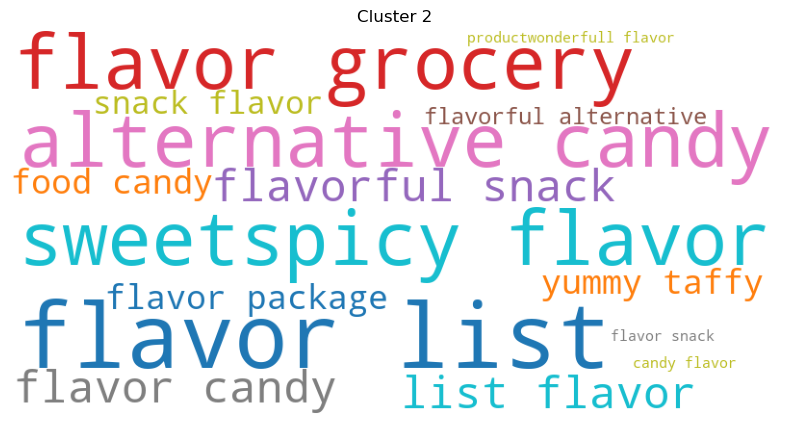

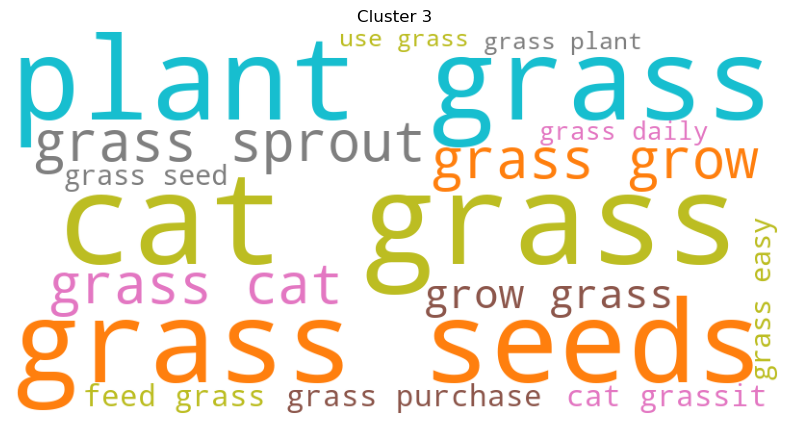

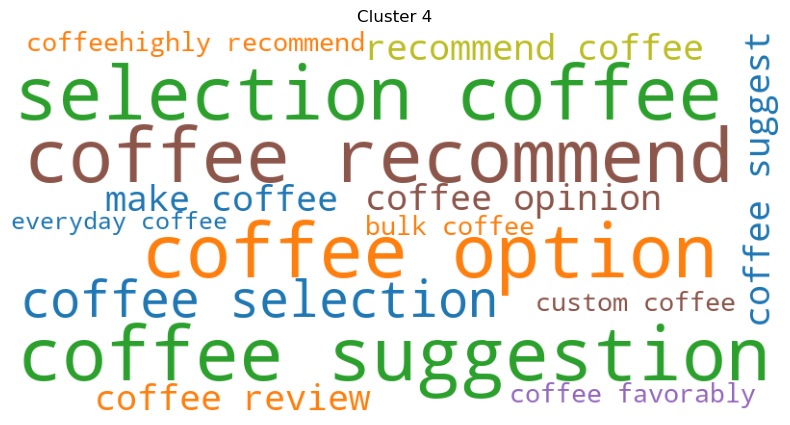

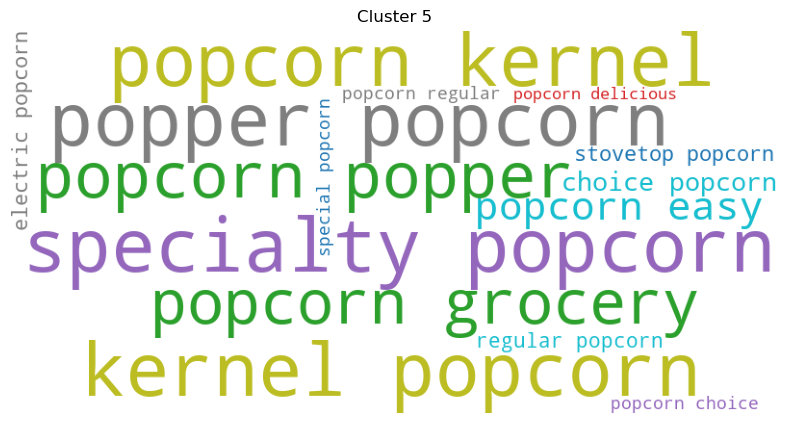

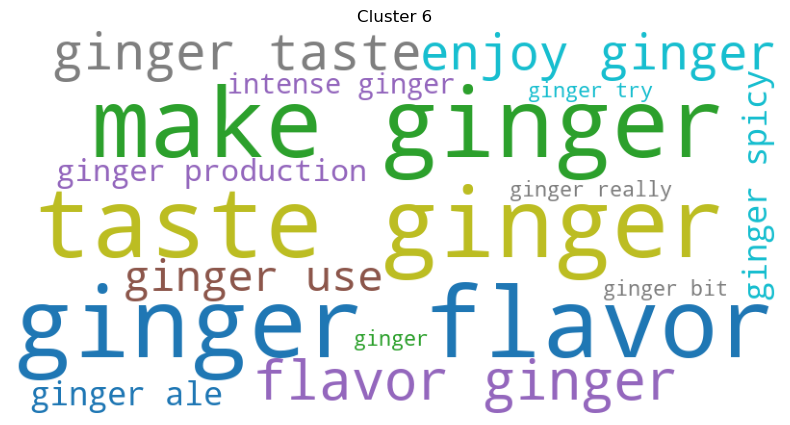

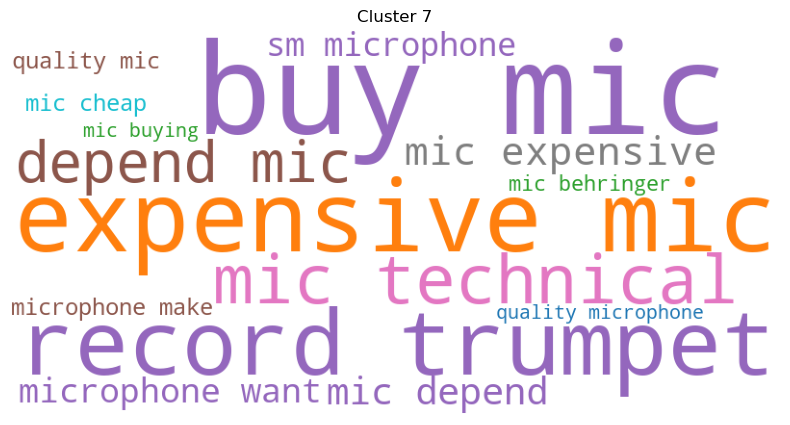

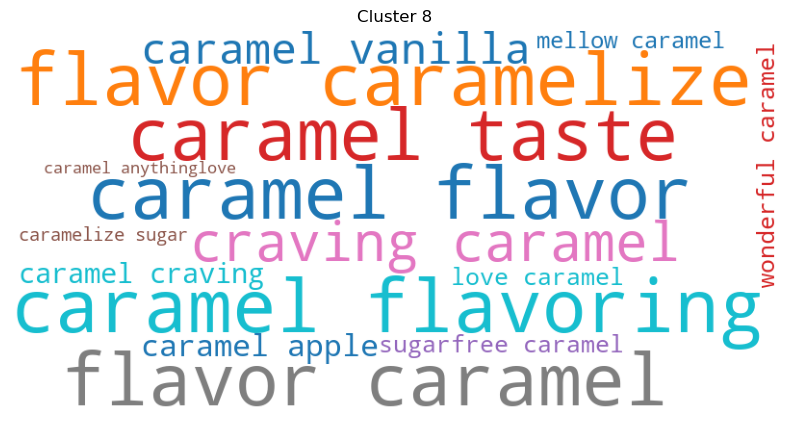

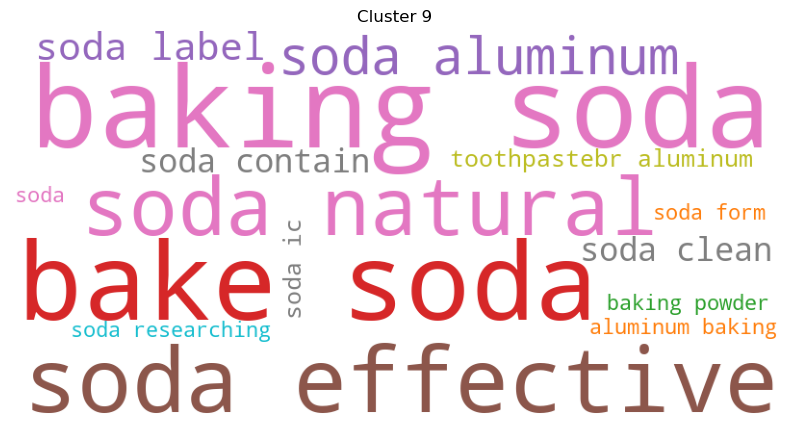

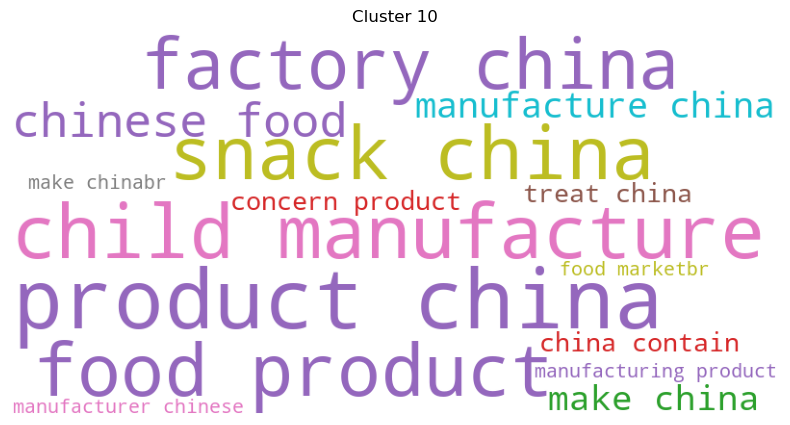

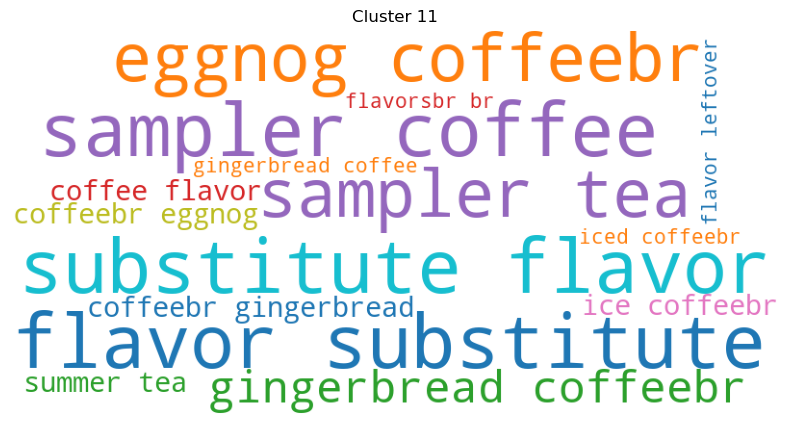

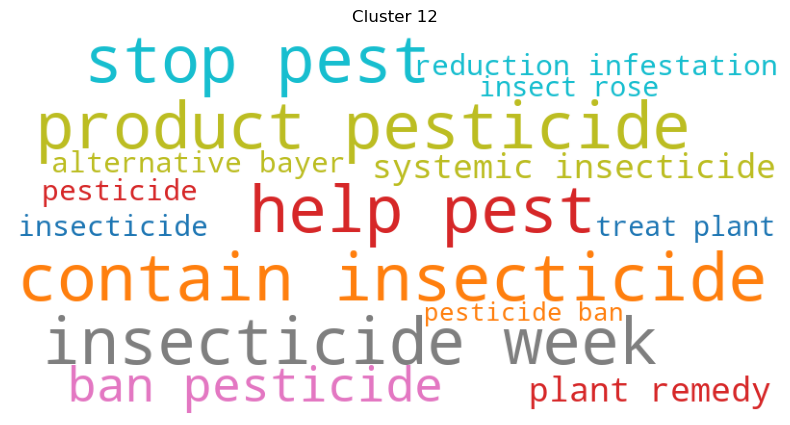

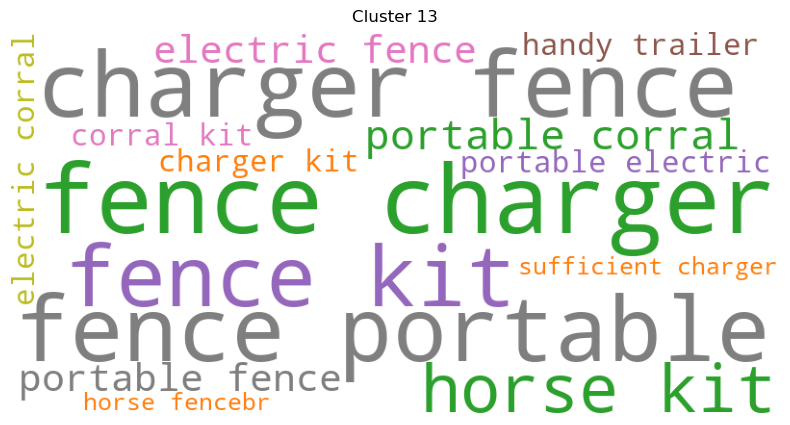

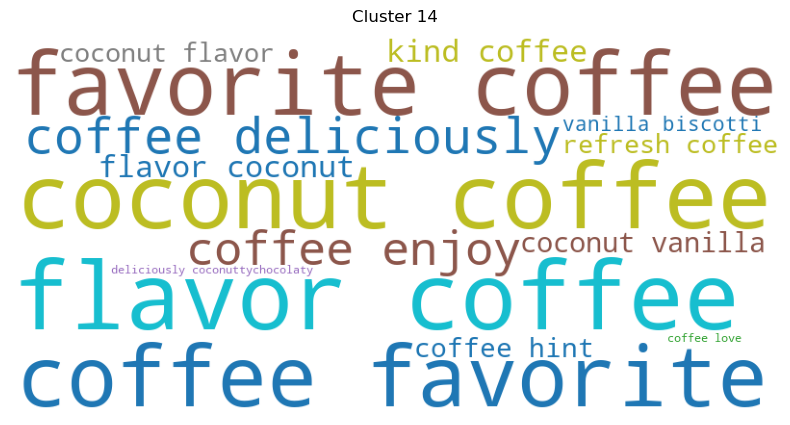

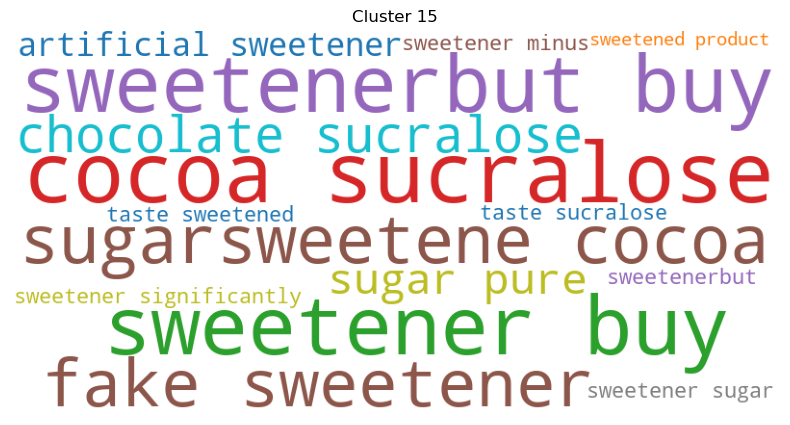

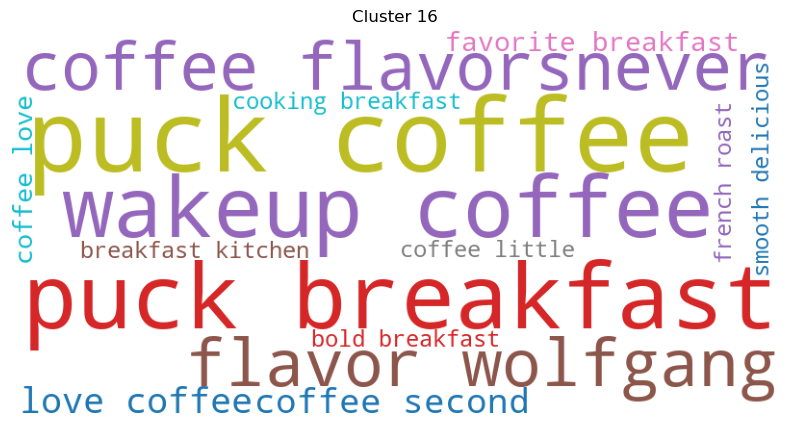

In [106]:
for i, cluster in enumerate(keywords):
    word_freq = dict(cluster)

    wc = WordCloud(
        width=800,
        height=400,
        background_color="white",
        colormap="tab10"
    ).generate_from_frequencies(word_freq)

    plt.figure(figsize=(10, 5))
    plt.title(f"Cluster {i}")
    plt.imshow(wc)
    plt.axis("off")
    plt.show()

# TF-IDF

# Кодирование текста

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [46]:
import torch

In [47]:
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df)
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=tfidf_vectorizer.get_feature_names_out())
df_tfidf.head()

,aa,aaaa,aadmit,aahhhs,aand,ab,aback,abandon,abate,abberline,...,zoom,zotz,zridge,zs,zucchini,zucchinibr,zuke,zukebr,zupas,zuppa
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [48]:
X_tfidf.shape

(10000, 20209)

# Понижаем размерность

In [49]:
from umap import UMAP

In [50]:
u = UMAP(n_components=2, n_neighbors=10).fit(X_tfidf)
emb_tfidf = u.transform(X_tfidf)

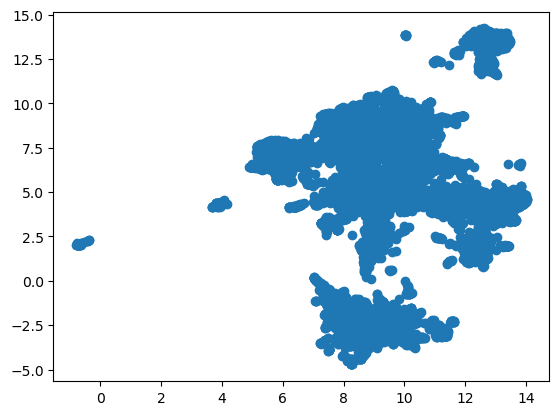

In [51]:
plt.scatter(emb_umap[:, 0], emb_umap[:, 1])

# Кластеризация

In [52]:
from sklearn.cluster import DBSCAN

In [71]:
dbscan = DBSCAN(eps=0.6, min_samples=5).fit(emb_tfidf)

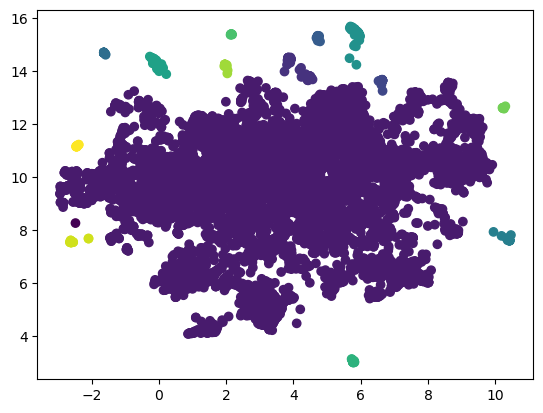

In [72]:
plt.scatter(emb_tfidf[:, 0], emb_tfidf[:, 1], c=dbscan.labels_)

In [73]:
len(np.unique(dbscan.labels_))

15

In [74]:
labels = dbscan.labels_

In [75]:
silhouette = silhouette_score(
    emb_tfidf,
    labels
)

In [76]:
dbi = davies_bouldin_score(
    emb_tfidf,
    labels
)

In [77]:
print("Silhouette:", silhouette)
print("DB:", dbi)

Silhouette: -0.26847142
DB: 0.6011053394612595


In [78]:
df_tfidf_topics = pd.DataFrame({
    'doc': docs[:n],
    'topic': dbscan.labels_
})

In [79]:
df_tfidf_topics['topic'].value_counts()

topic
 0     9528
 6      108
 7       78
 1       63
 5       51
 8       33
 4       25
 3       23
 11      22
 2       17
 12      16
 10      15
 13      12
 9        8
-1        1
Name: count, dtype: int64

# Объединяем документы одного класса в один документ

In [80]:
docs_per_class = df_tfidf_topics.groupby(['topic'], as_index=False).agg({'doc': ' '.join})

In [81]:
docs_per_class.head()

,topic,doc
0,-1,quite pleased e flavor product good strong yet...
1,0,buy several vitality can dog food product find...
2,1,twizzler strawberry childhood favorite candy m...
3,2,order olive lot unlike olive subtle flavor bri...
4,3,buy local specialtyitem store adore chutney hi...


In [82]:
vectorizer = TfidfVectorizer(ngram_range=(1,2))
tf_idf = vectorizer.fit_transform(docs_per_class['doc']).toarray()

In [83]:
tf_idf.shape

(15, 237139)

In [84]:
k = 15
words = vectorizer.get_feature_names_out() 
labels = list(docs_per_class['topic'])
indices = tf_idf.argsort()[:, -k:]
top_n_words = [[(words[j], tf_idf[i][j]) for j in indices[i]][::-1] for i, label in enumerate(labels)]

# Топовые слова

In [85]:
top_n_words

[[('flavor', 0.27317126229775707),
  ('strong yet', 0.24737292635102187),
  ('please highly', 0.24737292635102187),
  ('pleased flavor', 0.24737292635102187),
  ('overpower flavor', 0.21480173155209878),
  ('yet overpower', 0.21480173155209878),
  ('quite pleased', 0.21480173155209878),
  ('highly recomend', 0.21480173155209878),
  ('recomend product', 0.21480173155209878),
  ('good strong', 0.21480173155209878),
  ('flavor rich', 0.21480173155209878),
  ('flavor please', 0.21480173155209878),
  ('chocolate flavor', 0.19169210106945506),
  ('flavor product', 0.19169210106945506),
  ('rich chocolate', 0.19169210106945506)],
 [('coffee', 0.33340314685398553),
  ('not', 0.19744627082158195),
  ('br', 0.19163321539374187),
  ('like', 0.19087501799139053),
  ('taste', 0.187755985221822),
  ('good', 0.15628542736802087),
  ('tea', 0.15340419488104667),
  ('flavor', 0.1531852544125514),
  ('make', 0.12553493951176045),
  ('cup', 0.12381226435544558),
  ('use', 0.12331374581267064),
  ('great'

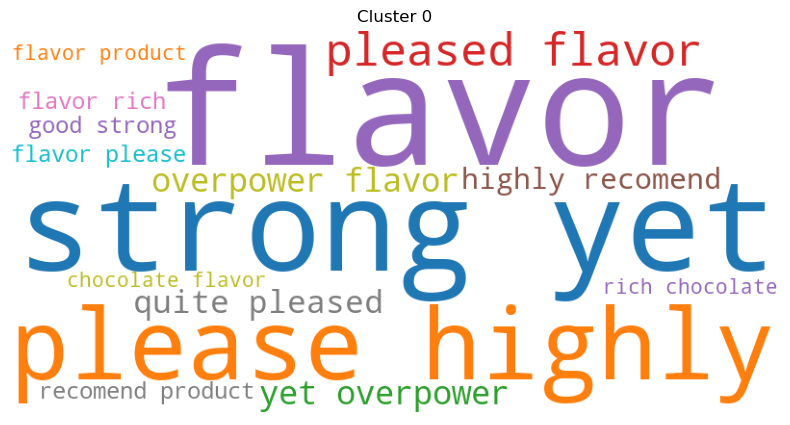

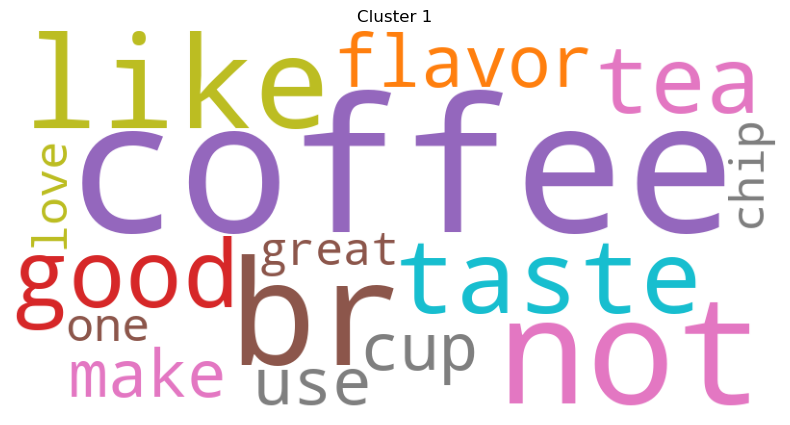

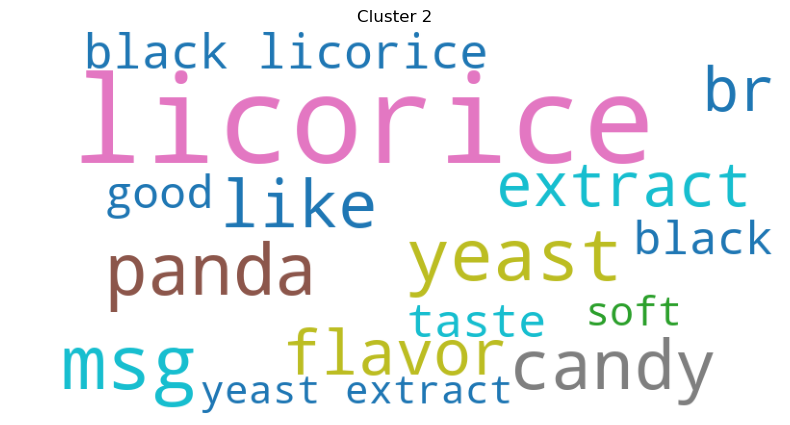

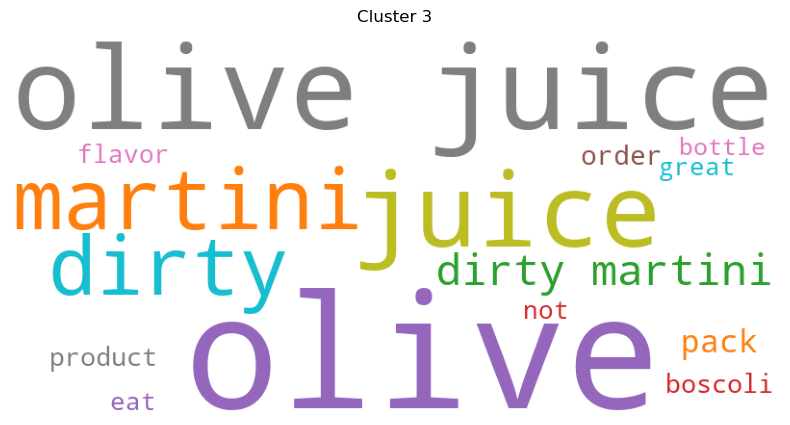

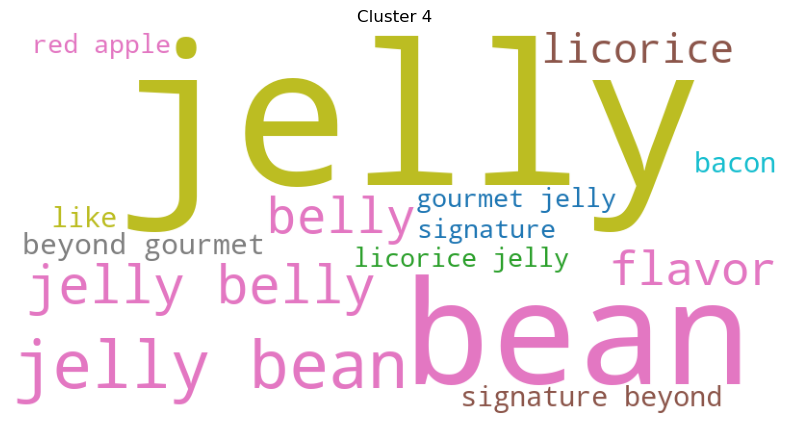

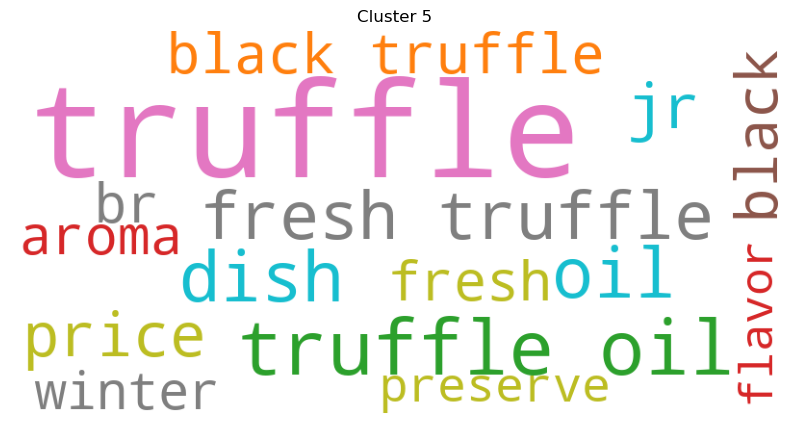

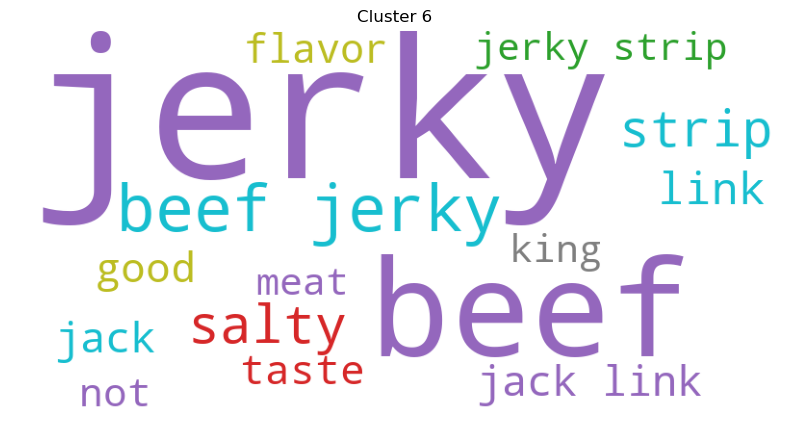

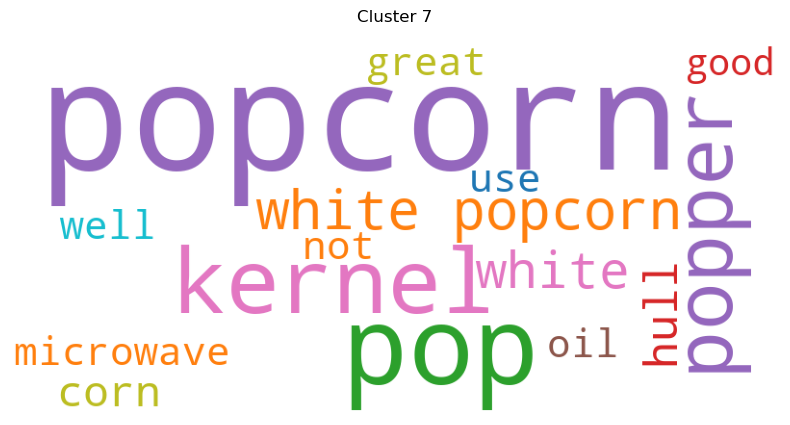

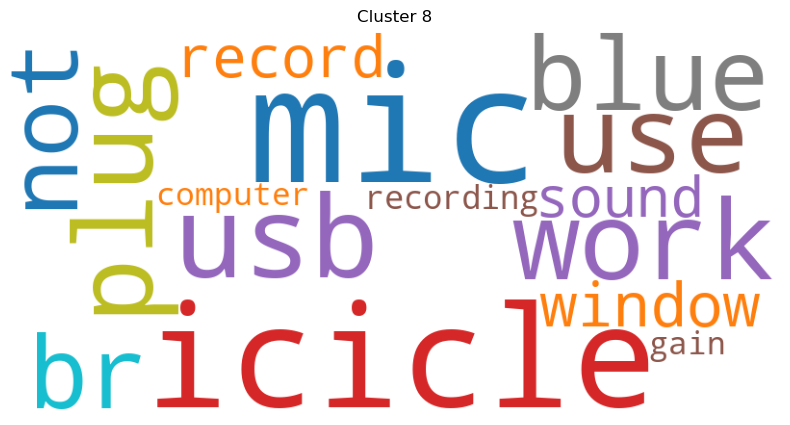

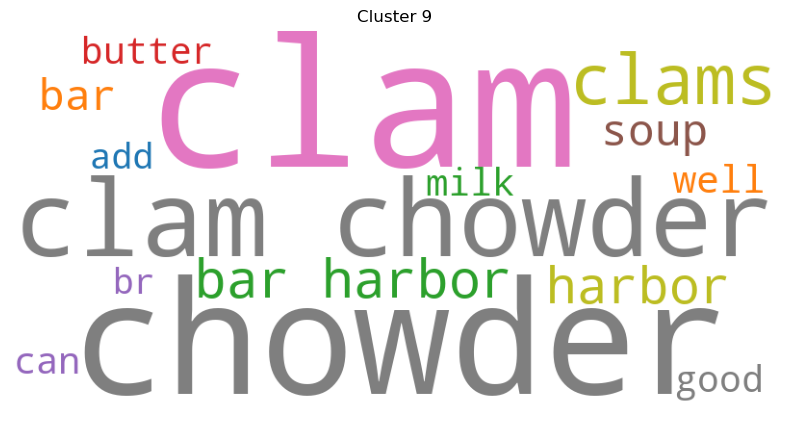

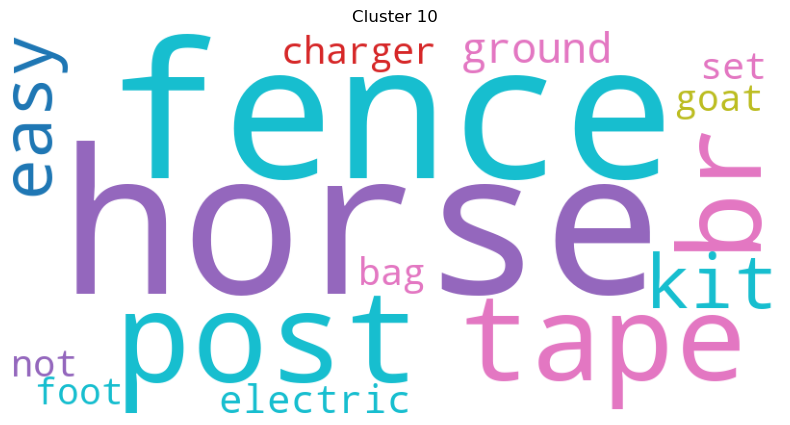

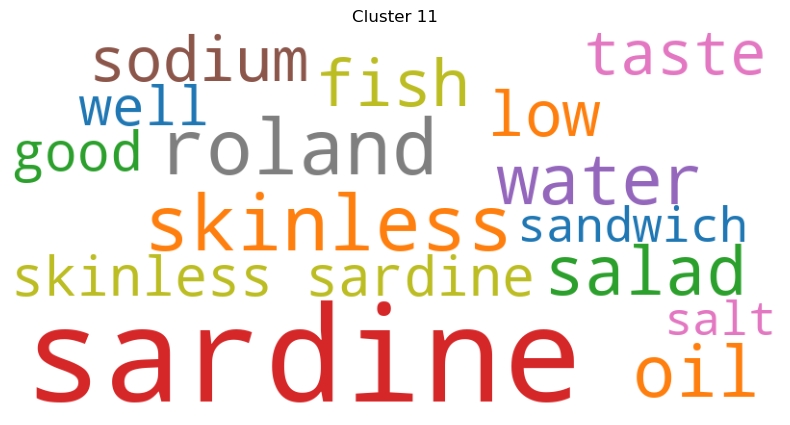

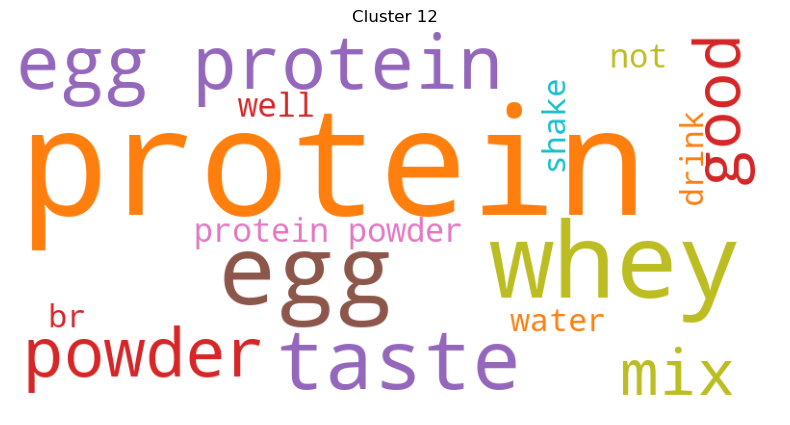

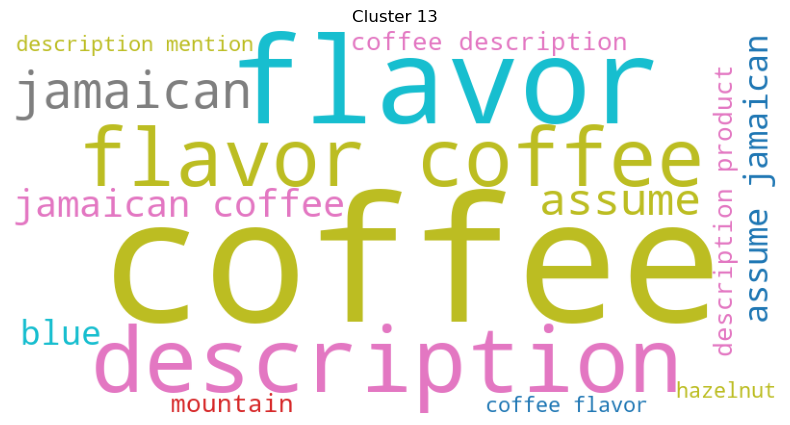

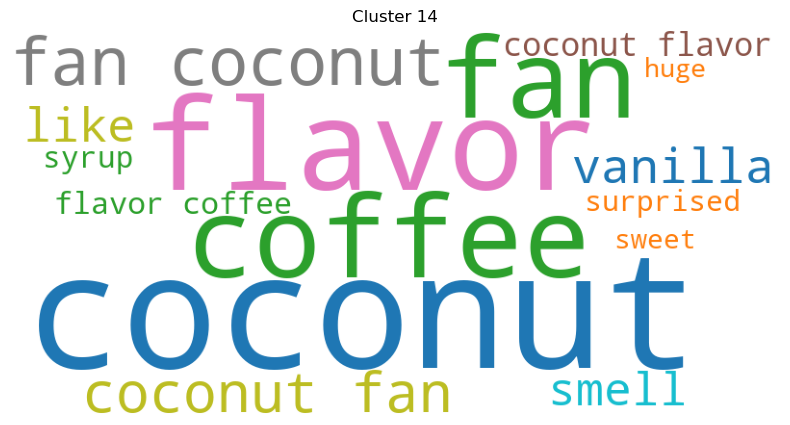

In [86]:
for i, cluster in enumerate(top_n_words):
    word_freq = dict(cluster)

    wc = WordCloud(
        width=800,
        height=400,
    ).generate_from_frequencies(word_freq)

    plt.figure(figsize=(10, 5))
    plt.title(f"Cluster {i}")
    plt.imshow(wc)
    plt.axis("off")
    plt.show()